In [1]:
import pandas as pd

data = pd.read_csv("amz_uk_price_prediction_dataset.csv")

data.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


### Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

#### Generate a frequency table for the product category.
Which are the top 5 most listed product categories?
Visualizations:

In [3]:
data["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

#### Display the distribution of products across different categories using a bar chart. 
If you face problems understanding the chart, do it for a subset of top categories.
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

<Axes: xlabel='category', ylabel='count'>

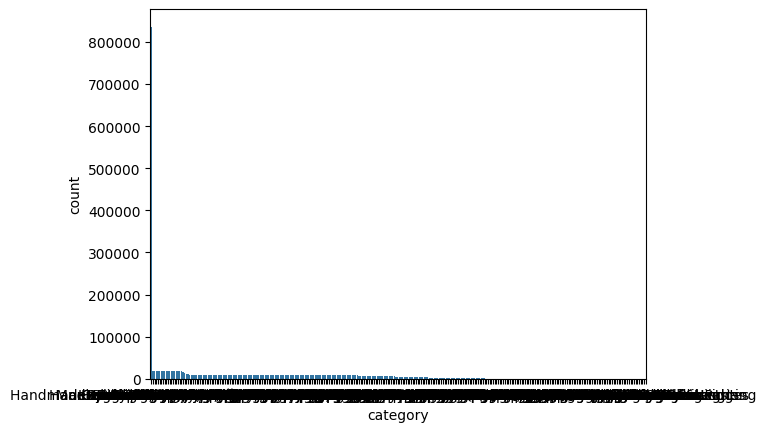

In [4]:
import seaborn as sns

sns.barplot(data["category"].value_counts())

Unredeable and unusefull. I switch to first 5 categories 

([<matplotlib.patches.Wedge at 0x31a6b6dd0>,
 [Text(-1.061989487463534, 0.2866676272566199, 'Sports & Outdoors'),
  Text(0.9852467003838558, -0.48917168702074837, 'Beauty'),
  Text(1.0412847474771803, -0.3545787284530543, 'Handmade Clothing, Shoes & Accessories'),
  Text(1.0788688426253243, -0.21457404412531686, 'Bath & Body'),
  Text(1.0976548098889691, -0.07179079556329825, 'Birthday Gifts')],
 [Text(-0.5792669931619276, 0.15636416032179262, '92%'),
  Text(0.5374072911184667, -0.2668209201931354, '2%'),
  Text(0.5679734986239164, -0.19340657915621143, '2%'),
  Text(0.5884739141592678, -0.11704038770471828, '2%'),
  Text(0.5987208053939831, -0.039158615761799034, '2%')])

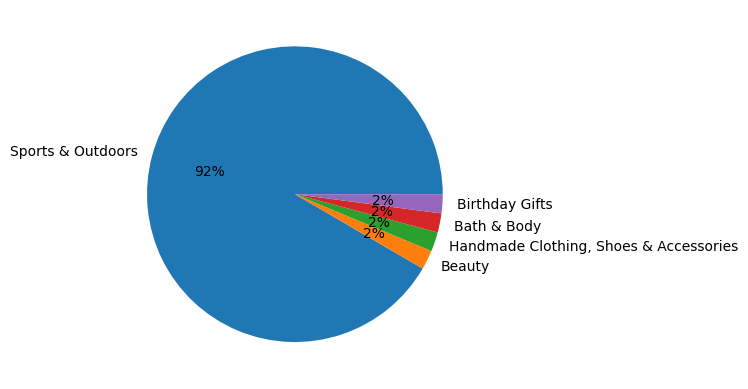

In [5]:
import matplotlib.pyplot as plt

labels = data["category"].value_counts().iloc[:5].index
plt.pie(data["category"].value_counts().iloc[:5], labels=labels, autopct='%.0f%%')

## Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?





### Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [6]:
pd.set_option('display.float_format', '{:.2f}'.format) # Make output without scientific notation e04...
print(f"Average price point: {data.price.mean()}") 
print(f"Mode: {data.price.mode()}")

Average price point: 89.24380943923661
Mode: 0   9.99
Name: price, dtype: float64


Mode is much smaller then average price. There are a lot of items with price 9.99 

### Determine the variance, standard deviation, range, and interquartile range for product price.
How varied are the product prices? Are there any indicators of a significant spread in prices?

In [7]:
data.price.describe()

count   2443651.00
mean         89.24
std         345.61
min           0.00
25%           9.99
50%          19.09
75%          45.99
max      100000.00
Name: price, dtype: float64

In [8]:
data.price.median()

19.09

The standart deviation is big, if we are also considering that mode is 9.99 and mean is 89.24. Median is much less then mean, hence there are quite a few items with high price that influence the mean

### Is there a specific price range where most products fall? 
Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..


<Axes: xlabel='price', ylabel='Count'>

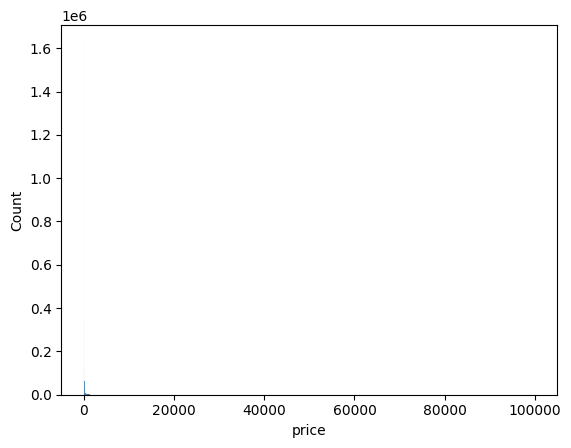

In [9]:
sns.histplot(data.price)

The price range is too big. There probably just one or two items with such a high price, but there are outliers. Because of them the histogram is unusable.

I will remove outliers for the histogram

<Axes: xlabel='price', ylabel='Count'>

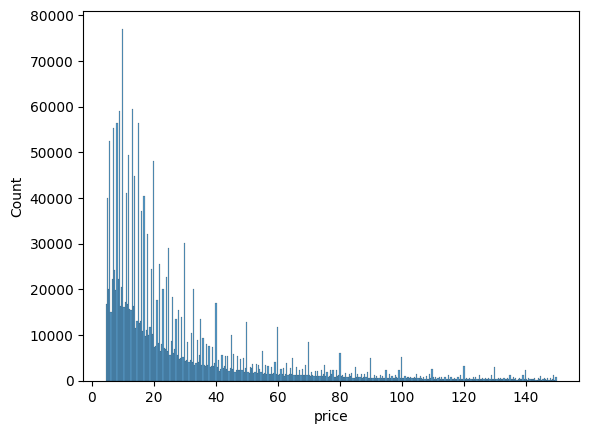

In [10]:
import numpy as np

q_low = data.price.quantile(0.05)
q_high = data.price.quantile(0.9)

values = data.loc[(data.price > q_low) & (data.price < q_high), "price"]
sns.histplot(values)

Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

<Axes: ylabel='price'>

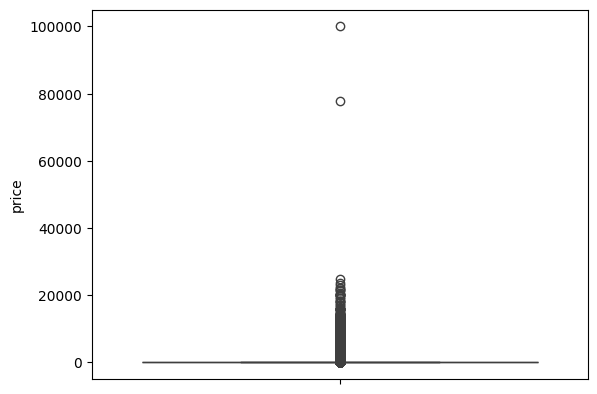

In [11]:
sns.boxplot(data.price)

As expected there is only 1 item with price 100000 and 1 item with price 80000.

<Axes: xlabel='price'>

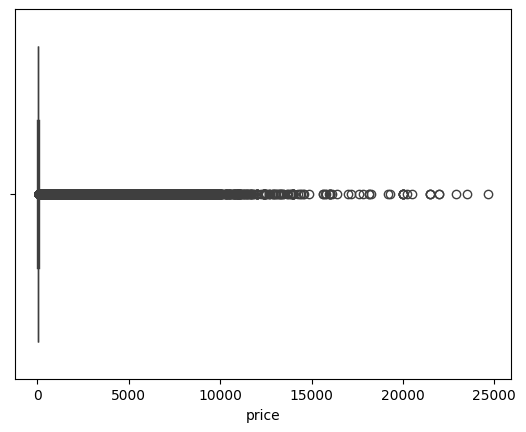

In [12]:
sns.boxplot(x = data.price.sort_values().iloc[:-2])

The plot without the obvious 2 outlliers looks a little bit more readable. Still we have a lot of outliers. Lets hide them

<Axes: xlabel='price'>

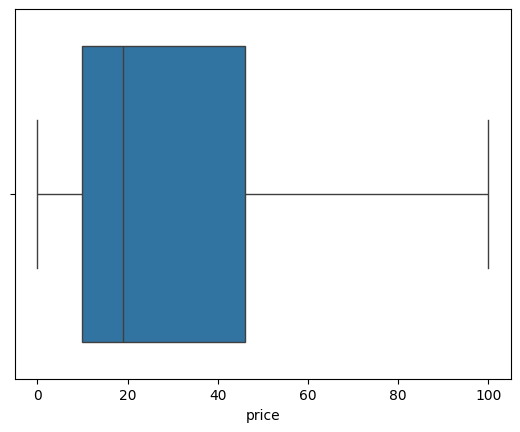

In [13]:
sns.boxplot(x = data.price.sort_values().iloc[:-2], showfliers = False)

## Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?



### Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?

In [14]:
print(f"Mean {data.stars.mean()}")
print(f"Median {data.stars.median()}")
print(f"Mode {data.stars.mode()[0]}")

Mean 2.152836472966066
Median 0.0
Mode 0.0


More then half of the products do not have rating (median == 0.0). Given that, mean is surprisingly almost in the middle (2.15)

I want to check statistics without stars == 0

In [15]:
print(f"Mean {data.stars[data.stars > 0.0].mean()}")
print(f"Median {data.stars[data.stars > 0.0].median()}")
print(f"Mode {data.stars[data.stars > 0.0].mode()[0]}")

Mean 4.319160762226911
Median 4.4
Mode 4.5


When users give rating they are very generous! Most of the time they give 4.5 (Mode). Mean and median are very close! So there is not a big number of outliers

I wonder if the Germans statistic is like that... Germany loves to give 4 stars and write "Everything is good!"

### Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [16]:
data.stars.describe()

count   2443651.00
mean          2.15
std           2.19
min           0.00
25%           0.00
50%           0.00
75%           4.40
max           5.00
Name: stars, dtype: float64

In [17]:
iqr_value = data["stars"].quantile(0.75) - data["stars"].quantile(0.25)
print(f"IQR: {iqr_value}")

IQR: 4.4


IQR includes almost all values, so there are hardly any outluers. Because of the unrated items there is a big distribution 

### Now without stars = 0.0

In [18]:
data.stars[data.stars > 0.0].describe()

count   1218010.00
mean          4.32
std           0.56
min           1.00
25%           4.10
50%           4.40
75%           4.60
max           5.00
Name: stars, dtype: float64

In [19]:
iqr_value = data.stars[data.stars > 0.0].quantile(0.75) - data.stars[data.stars > 0.0].quantile(0.25)
print(f"IQR: {iqr_value}")

IQR: 0.5


Now we clearly see that the std and IQR are influenced A LOT by stars = 0.0! Apparently users tend to give 4.32 +- 0.56 rating. Very happy users (Or aliexpress style, when without rating the system gives 5 stars(which is kinda fair, because users usually love to complain))

### Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values?

### Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

<Axes: xlabel='stars', ylabel='Count'>

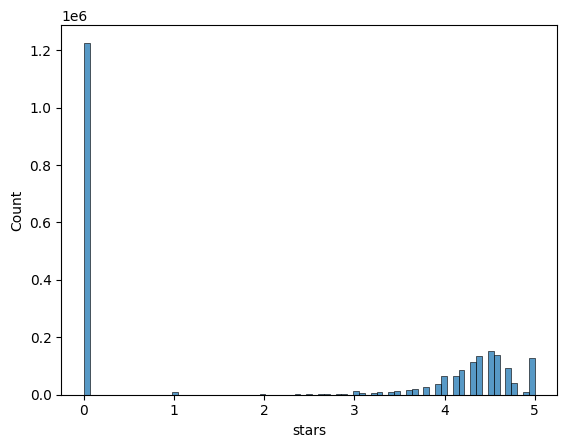

In [20]:
sns.histplot(data.stars)

Finally we can visually look at out big 0 pile that ruins statistics! Lets get rid of it!

<Axes: xlabel='stars', ylabel='Count'>

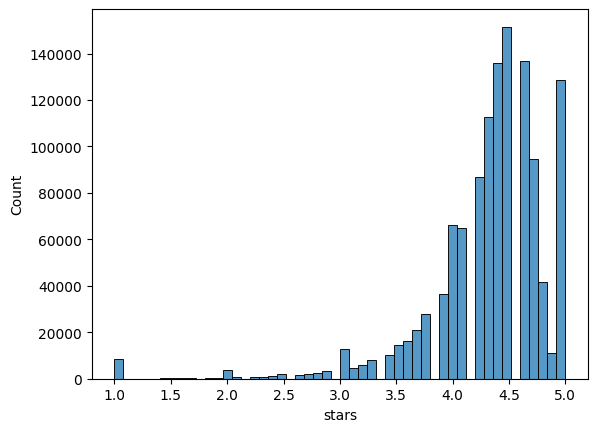

In [24]:
sns.histplot(data.stars[data.stars > 0.0], bins=50) # without bins the plot is too scars and unreadable